# The Path Less Travelled

This notebook will contain all the driving code for my honours project including synthetic data generation, real data preprocessing, model training, and evaluation. 

In [1]:
from wanderer import *
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#load the OUP process from json
OUP_process = StochasticProcess.from_json('OUP_process_EM_orig.json')

Text(0, 0.5, 'Value')

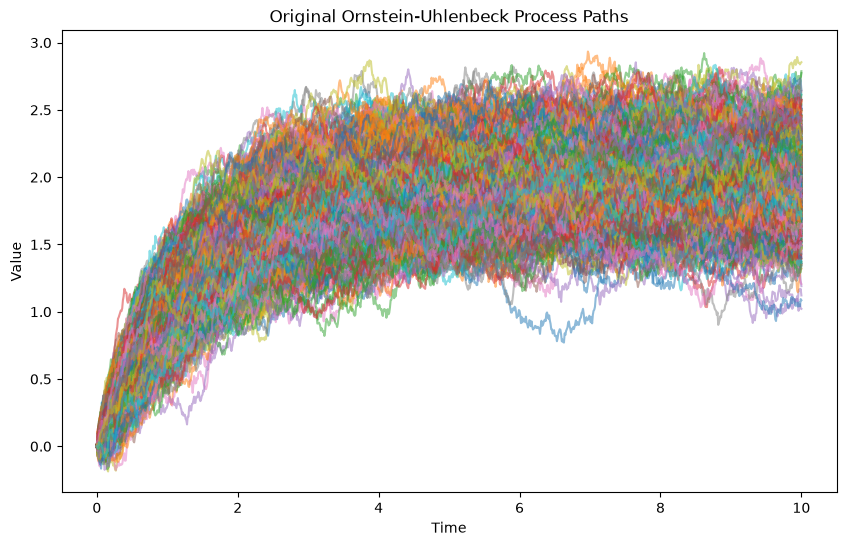

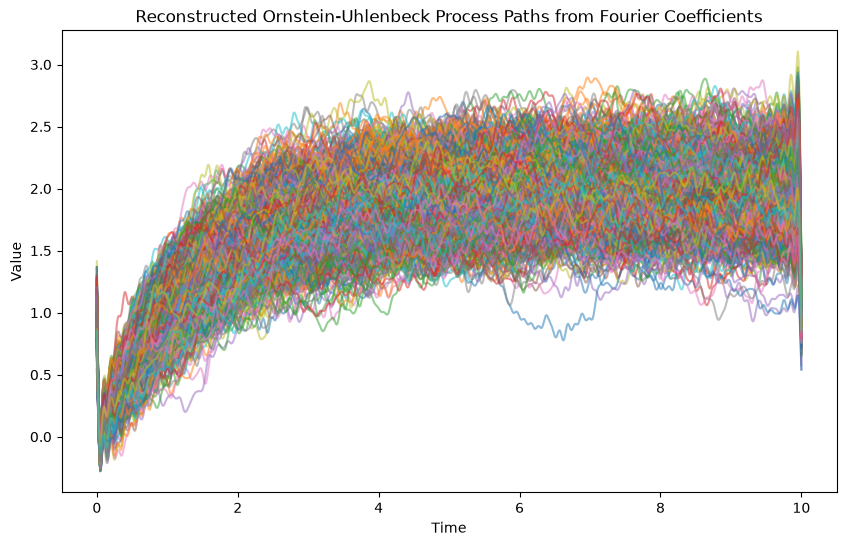

In [3]:
#Fourier decomp the OUP
coeffs = fourierDecomposition(100, OUP_process)

# #plot distribution of each coefficient across columns
# for i in range(coeffs.shape[1]):
#     plt.figure(figsize=(10, 6))
#     plt.hist(coeffs[:, i], bins=30, density=True, alpha=0.5)
#     plt.title(f'Distribution of Fourier Coefficient {i+1}')
#     plt.xlabel('Coefficient Value')
#     plt.ylabel('Density')
#     plt.show()

#reconstruct the process from the Fourier coefficients
reconstructed_process = reconstructFromFourier(coeffs, OUP_process.timeGrid, OUP_process.timeHorizon)

#plot the original and reconstructed process on seperate plots
plt.figure(figsize=(10, 6))
for i in range(OUP_process.num_paths):
    plt.plot(OUP_process.timeGrid, OUP_process.paths[i], alpha=0.5)
plt.title('Original Ornstein-Uhlenbeck Process Paths')
plt.xlabel('Time')
plt.ylabel('Value')

plt.figure(figsize=(10, 6))
for i in range(reconstructed_process.num_paths):
    plt.plot(reconstructed_process.timeGrid, reconstructed_process.paths[i], alpha=0.5)
plt.title('Reconstructed Ornstein-Uhlenbeck Process Paths from Fourier Coefficients')
plt.xlabel('Time')
plt.ylabel('Value')






Text(0, 0.5, 'Average Square Error')

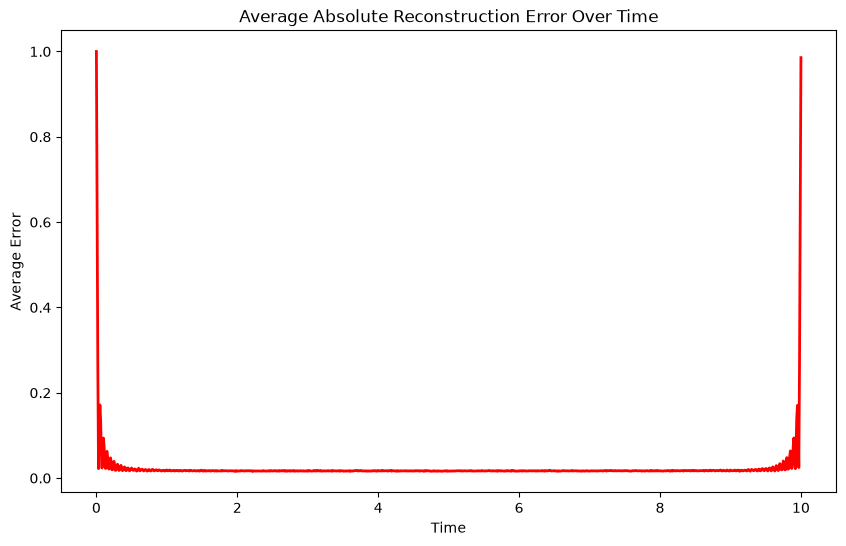

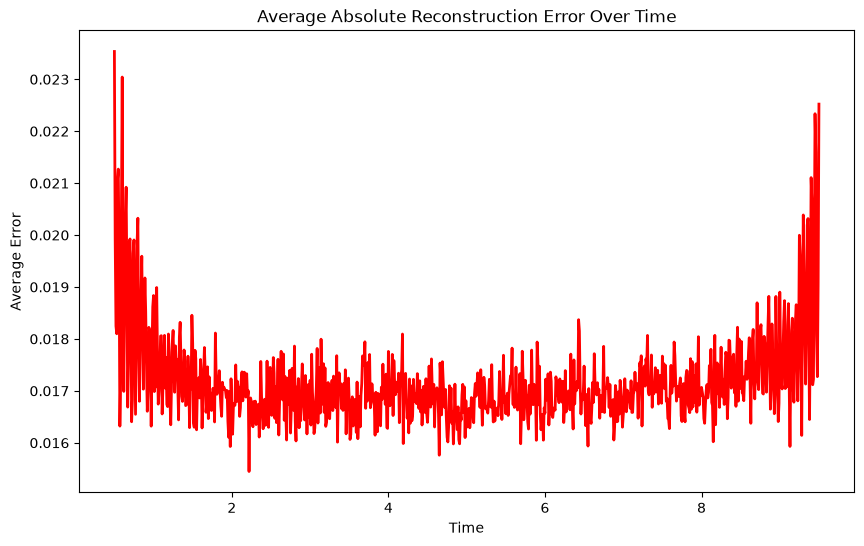

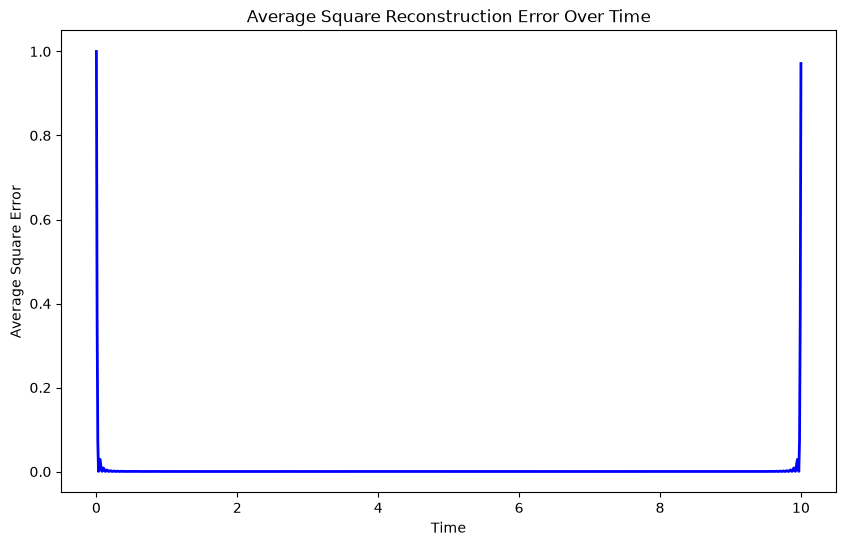

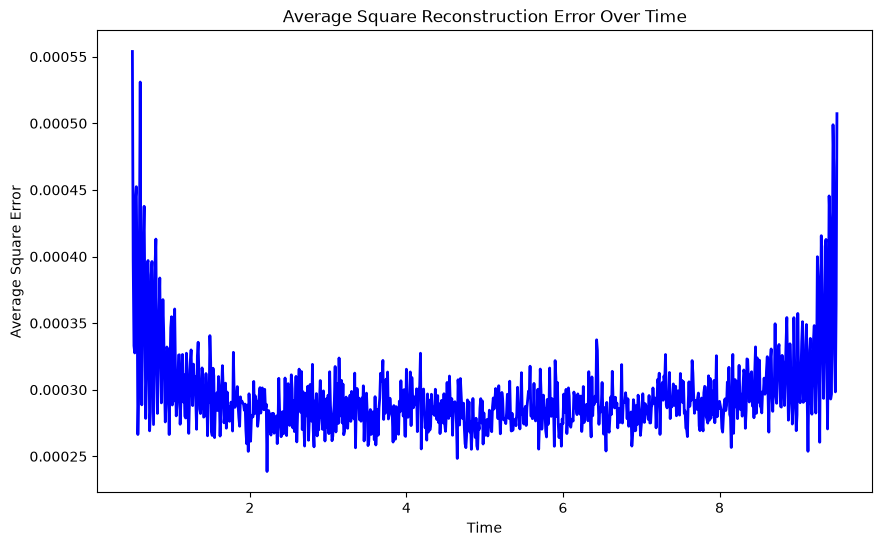

In [4]:
# compute the average reconstruction error at each time step 
errors = np.abs(reconstructed_process.paths - OUP_process.paths)
avg_errors = np.mean(errors, axis=0)
#plot the average reconstruction error over time
plt.figure(figsize=(10, 6))
plt.plot(OUP_process.timeGrid, avg_errors, color='red', linewidth=2)
plt.title('Average Absolute Reconstruction Error Over Time')
plt.xlabel('Time')
plt.ylabel('Average Error')

#plot the average reconstruction error over time excluding the first 10 and last 10 time steps

plt.figure(figsize=(10, 6))
plt.plot(OUP_process.timeGrid[50:-50], avg_errors[50:-50], color='red', linewidth=2)
plt.title('Average Absolute Reconstruction Error Over Time')
plt.xlabel('Time')
plt.ylabel('Average Error')

#plot the average square reconstruction error over time
plt.figure(figsize=(10, 6))
plt.plot(OUP_process.timeGrid, np.square(avg_errors), color='blue', linewidth=2)
plt.title('Average Square Reconstruction Error Over Time')
plt.xlabel('Time')
plt.ylabel('Average Square Error')

#plot the average square reconstruction error over time excluding the first 10 and last 10 time steps
plt.figure(figsize=(10, 6))
plt.plot(OUP_process.timeGrid[50:-50], np.square(avg_errors[50:-50]), color='blue', linewidth=2)
plt.title('Average Square Reconstruction Error Over Time')
plt.xlabel('Time')
plt.ylabel('Average Square Error')

In [13]:


# # load the sp500 process from json
# sp500_process = StochasticProcess.from_json('sp500_process.json')

# #time slice the sp500 process to only include the first 15 years of data
# sp500_process_sliced = sp500_process.time_slice(0, 15)

# #predict the next 5 years of the sp500 process using the fourier decomposition method
# sp500_predicted_process = predictBeyondHorizon(sp500_process_sliced, 20, 100)

# #plot the original and predicted sp500 process on the same plot
# plt.figure(figsize=(10, 6))
# plt.plot(sp500_process.timeGrid, sp500_process.paths[0], label='Original S&P 500 Process', color='blue')
# plt.plot(sp500_predicted_process.timeGrid, sp500_predicted_process.paths[0], label='Predicted S&P 500 Process', linestyle='--', color='red')
# #add 15 year line
# plt.axvline(x=15, color='green', linestyle=':', label='15-Year Mark')
# plt.title('Original and Predicted S&P 500 Process')
# plt.xlabel('Time (Years)')
# plt.ylabel('Value')
# plt.legend()
# plt.show()


In [14]:
#slice the OUP process to one year intervals and stack them into a new process
sliced_processes = []
for i in range(0, OUP_process.timeHorizon, 1):
    sliced_processes.append(OUP_process.time_slice(i, i+1))

#stack the paths of the sliced processes into a new array
for i in range(len(sliced_processes)):
    if i == 0:
        stacked_paths = sliced_processes[i].paths
    else:
        stacked_paths = np.vstack((stacked_paths, sliced_processes[i].paths))

#find new time horizon
new_time_horizon = 1

# create a new process with the stacked paths
new_process = StochasticProcess(paths=stacked_paths, timeHorizon=new_time_horizon, timeStep=OUP_process.timeStep, method='stacked', num_paths=stacked_paths.shape[0])

#print dim of original process and new process
print(f'Original Process Shape: {OUP_process.paths.shape}')
print(f'New Process Shape: {new_process.paths.shape}')

#derive the fourier coefficients of the new process
new_coeffs = fourierDecomposition(1000, new_process)



Original Process Shape: (1000, 1001)
New Process Shape: (10000, 100)


Text(0, 0.5, 'Value')

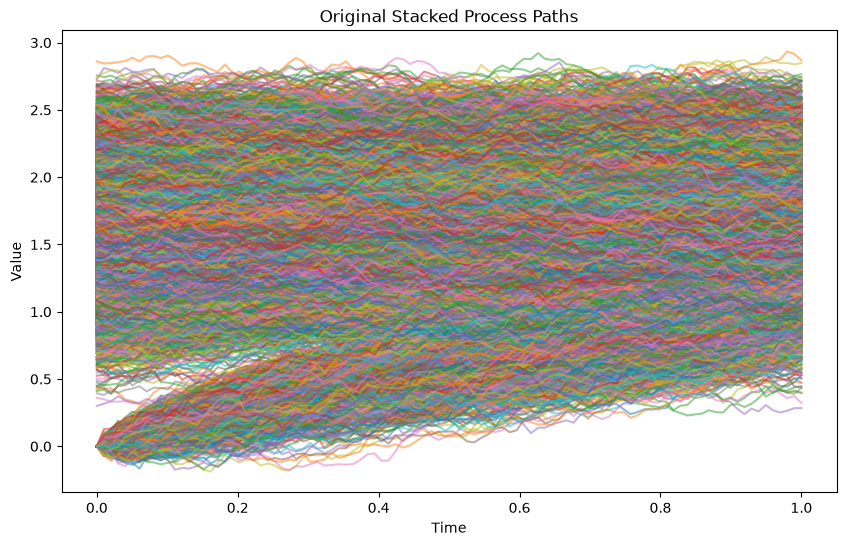

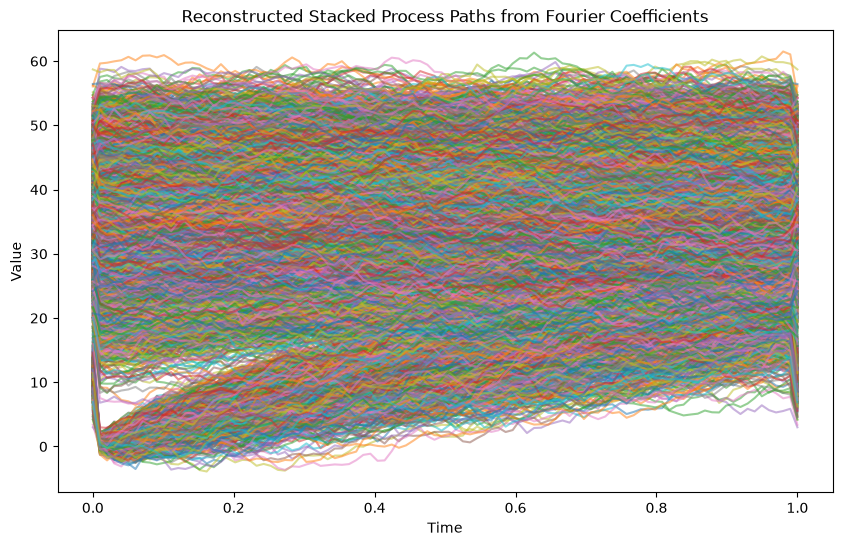

In [15]:
##reconstruct the new process from the Fourier coefficients
reconstructed_new_process = reconstructFromFourier(new_coeffs, new_process.timeGrid, new_process.timeHorizon)

#plot the original and reconstructed new process on seperate plots
plt.figure(figsize=(10, 6))
for i in range(new_process.num_paths):
    plt.plot(new_process.timeGrid, new_process.paths[i], alpha=0.5)
plt.title('Original Stacked Process Paths')
plt.xlabel('Time')
plt.ylabel('Value')

plt.figure(figsize=(10, 6))
for i in range(reconstructed_new_process.num_paths):
    plt.plot(reconstructed_new_process.timeGrid, reconstructed_new_process.paths[i], alpha=0.5)
plt.title('Reconstructed Stacked Process Paths from Fourier Coefficients')
plt.xlabel('Time')
plt.ylabel('Value')

In [16]:
#print shape of coeffs
print(f'Fourier Coefficients Shape: {new_coeffs.shape}')

Fourier Coefficients Shape: (10000, 2001)


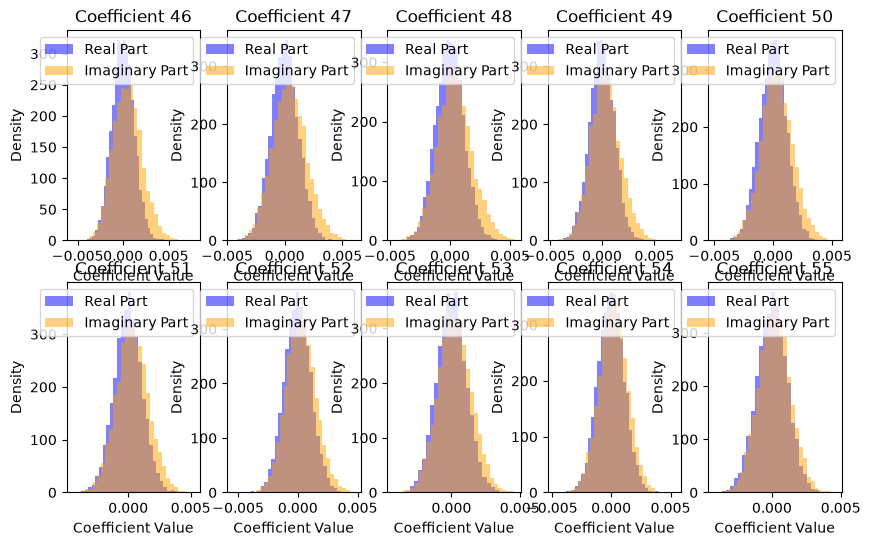

In [ ]:
#plot the empirical distribution of the real and imaginary parts of the middle 10 Fourier coefficients of the new process
plt.figure(figsize=(10, 8))
for i in range(45, 55):
    plt.subplot(2, 5, i-44)
    plt.hist(new_coeffs[:, i].real, bins=30, density=True, alpha=0.5, color='blue', label='Real Part')
    plt.hist(new_coeffs[:, i].imag, bins=30, density=True, alpha=0.5, color='orange', label='Imaginary Part')
    plt.title(f'Coefficient {i+1}')
    plt.xlabel('Coefficient Value')
    plt.ylabel('Density')
    plt.legend()

In [6]:
# undertake out of time simulation for a time period of 10 year
out_of_time_simulation = outOfTimeSimulation(distributions=coeffs, time_horizon=10, time_step=OUP_process.timeStep, num_paths=100)



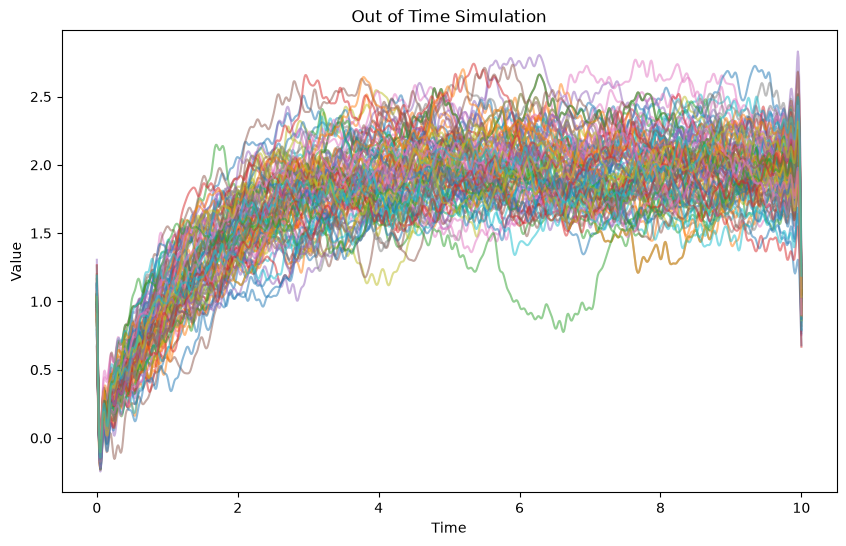

NameError: name 'new_process' is not defined

<Figure size 1000x600 with 0 Axes>

In [7]:
#plot the sample paths of the out of time simulation
plt.figure(figsize=(10, 6))
for i in range(out_of_time_simulation.num_paths):
    plt.plot(out_of_time_simulation.timeGrid, out_of_time_simulation.paths[i], alpha=0.5)
plt.title('Out of Time Simulation')
plt.xlabel('Time')
plt.ylabel('Value')
plt.show()

#plot the stacked sample paths
plt.figure(figsize=(10, 6))
for i in range(new_process.num_paths):
    plt.plot(new_process.timeGrid, new_process.paths[i], alpha=0.5)
plt.title('Out of Time Simulation')
plt.xlabel('Time')
plt.ylabel('Value')
plt.show()

In [ ]:
print("all done!")